Neuron Model

In [2]:
class Neuron:
  def __init__(self, resting_potential=-70, threshold=-55, current_potential=-70, neuron_type="excitatory"):
    self.resting_potential=resting_potential
    self.threshold=threshold
    self.current_potential=current_potential
    self.neuron_type=neuron_type
  def receive_stimulus(self):
    stimulus=int(input("Enter the stimulus:"))
    self.current_potential += stimulus
    self.fire()
  def fire(self):
    if self.current_potential >= self.threshold:
      print("Fire!")
    else:
      print("The stimulus is below threshold value.No Action Potential generated!")
  def reset(self):
     self.current_potential = self.resting_potential
     print("Reset")
 #Added later at 4th Commit:
  def connect_to(self, neuron):
     self.connected_neuron = neuron
     print("Neuron connected!")
  def send_signal(self):
    if self.connected_neuron is not None:
        signal = int(input("Enter the stimulus: "))
        if self.neuron_type == "excitatory":
          self.connected_neuron.current_potential += signal
        elif self.neuron_type == "inhibitory":
          self.connected_neuron.current_potential -= signal
        print("Signal sent!")
        self.connected_neuron.fire()

        print("Signal sent!")
        self.connected_neuron.fire()

In [ ]:
#Creating an Object
neuron=Neuron()
neuron.receive_stimulus()

Enter the stimulus:45
Fire!


In [ ]:
neuron=Neuron()
neuron.fire()

The stimulus is below threshold value.No Action Potential generated!


In [ ]:
neuron=Neuron()
neuron.reset()

Reset


Action-Potential

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100]


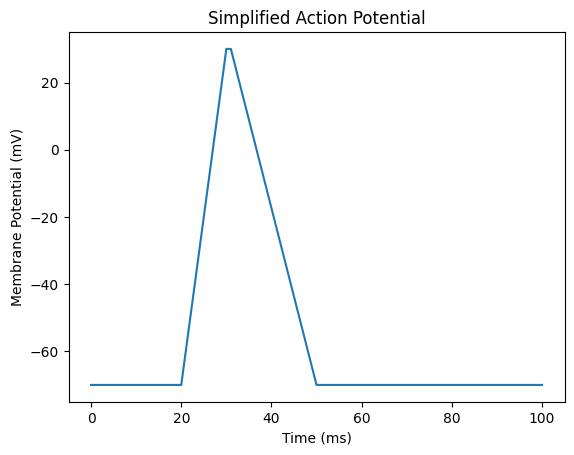

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
time = np.arange(0, 101, 1)
print(time)
potential = np.full(len(time), -70.0)
potential[20:31] = np.linspace(-70, 30, 11)
potential[31:51] = np.linspace(30, -70, 20)
potential[51:] = -70
plt.plot(time, potential)
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.title("Simplified Action Potential")
plt.show()

Multiple Neurons

In [ ]:
neuron1=Neuron()
neuron1.receive_stimulus()
neuron2=Neuron()
neuron2.receive_stimulus()
neuron3=Neuron()
neuron3.receive_stimulus()

Enter the stimulus:4
The stimulus is below threshold value.No Action Potential generated!
Enter the stimulus:78
Fire!
Enter the stimulus:90
Fire!


In [ ]:
neurons = [Neuron(), Neuron(), Neuron()]
print(len(neurons))
for neuron in neurons:
    neuron.receive_stimulus()

3
Enter the stimulus:23
Fire!
Enter the stimulus:1
The stimulus is below threshold value.No Action Potential generated!
Enter the stimulus:70
Fire!


Neuron Connections

In [ ]:
neuron1 = Neuron()
neuron2 = Neuron()
neuron3 = Neuron()
neuron4 = Neuron()
neuron5=Neuron()
neuron1.connect_to(neuron2)
neuron2.connect_to(neuron3)
neuron3.connect_to(neuron4)
neuron4.connect_to(neuron5)

Neuron connected!
Neuron connected!
Neuron connected!
Neuron connected!


In [ ]:
neuron1.connect_to(neuron2)
neuron1.send_signal()
print("Neuron 2 potential:", neuron2.current_potential)

Neuron connected!
Enter the stimulus:78
Signal sent!
Fire!
Neuron 2 potential: 53


In [ ]:
neuron1.send_signal()

Enter the stimulus: 34
Signal sent!
Fire!
Enter the stimulus: 67
Signal sent!
Fire!
Enter the stimulus: 1
Signal sent!
The stimulus is below threshold value.No Action Potential generated!


In [ ]:
print("Neuron 1:", neuron1.current_potential)
print("Neuron 2:", neuron2.current_potential)
print("Neuron 3:", neuron3.current_potential)
print("Neuron 4:", neuron4.current_potential)

Neuron 1: -70
Neuron 2: -36
Neuron 3: -3
Neuron 4: -69


Excitatory & Inhibitory Neurons

In [3]:
neuron1=Neuron(neuron_type="excitatory")
neuron2=Neuron()
neuron1.connect_to(neuron2)
neuron1.send_signal()
print("Neuron 2 potential:",neuron2.current_potential)

Neuron connected!
Enter the stimulus: 67
Signal sent!
Fire!
Signal sent!
Fire!
Neuron 2 potential: -3


In [6]:
neuron3 = Neuron(neuron_type="inhibitory")
neuron4 = Neuron()
neuron3.connect_to(neuron4)
neuron3.send_signal()
print("Neuron 4 potential:", neuron4.current_potential)

Neuron connected!
Enter the stimulus: 10
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
Neuron 4 potential: -80


In [7]:
excitatory_neuron = Neuron(neuron_type="excitatory")
inhibitory_neuron = Neuron(neuron_type="inhibitory")
target_neuron = Neuron()
excitatory_neuron.connect_to(target_neuron)
inhibitory_neuron.connect_to(target_neuron)
excitatory_neuron.send_signal()
print("After excitatory signal:", target_neuron.current_potential)
target_neuron.reset()
inhibitory_neuron.send_signal()
print("After inhibitory signal:", target_neuron.current_potential)

Neuron connected!
Neuron connected!
Enter the stimulus: 56
Signal sent!
Fire!
Signal sent!
Fire!
After excitatory signal: -14
Reset
Enter the stimulus: 10
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
Signal sent!
The stimulus is below threshold value.No Action Potential generated!
After inhibitory signal: -80
